# Regressão Linear Múltipla: Modelagem Econômica, Multicolinearidade e Diagnóstico

**Projeto:** Data Science & Machine Learning Practice  
**Módulo:** 04 - Modelos Lineares: Regressão Linear Múltipla  
**Dataset Base:** Indicadores Econômicos e Índice de Preços (`economic_index.csv`)  

---

## Objetivo Deste Notebook
O objetivo deste módulo é aprofundar o estudo dos modelos lineares expandindo a regressão para **múltiplas variáveis preditoras independentes**. Analisei o impacto simultâneo da **Taxa de Juros (*Interest Rate*)** e da **Taxa de Desemprego (*Unemployment Rate*)** sobre o **Índice de Preços (*Index Price*)**.

Ao longo deste notebook, corrijo rigorosamente as armadilhas metodológicas identificadas na aula prática original:
1. **Correção do Vazamento de Dados com `fit_transform`:** Corrigir a falha metodológica grave de aplicar `fit_transform` no conjunto de teste, demonstrando empiricamente o ganho real de desempenho com a transformação consistente (`transform`).
2. **Diagnóstico da Multicolinearidade Severa:** Identificar o "elefante na sala" ignorado na aula — a correlação extrema de $-0{,}93$ entre juros e desemprego — e calcular formalmente o **VIF (*Variance Inflation Factor*)**.
3. **Correção do Intercepto no `statsmodels`:** Demonstrar lado a lado o sumário quebrado da aula (onde a falta de constante gerou $R^2 = 3{,}5\%$ e $p = 0{,}89$) contra a implementação correta via `sm.add_constant()` ($R^2 = 90{,}3\%$).
4. **Avaliação Comparativa contra Baseline Ingênuo:** Comparar o modelo preditivo contra o chute simples da média (`DummyRegressor`).
5. **Auditoria Completa de Resíduos:** Verificar as suposições clássicas de Gauss-Markov (homocedasticidade e normalidade via Q-Q Plot e teste de Shapiro-Wilk).

## 1. Setup e Importação de Bibliotecas

Importo o ferramental científico para manipulação tabular (`pandas`, `numpy`), visualização estatística (`matplotlib`, `seaborn`), aprendizado de máquina (`scikit-learn`), além de inferência estatística rigorosa e cálculo do VIF (`statsmodels` e `scipy.stats`).

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Supressão de avisos para manter a saída limpa
warnings.filterwarnings('ignore')

# Configurações estéticas padrão para os gráficos
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

print("Ambiente configurado com sucesso!")

Ambiente configurado com sucesso!


## 2. Carregamento dos Dados com Busca Flexível

Adoto a estratégia de busca multi-path para carregar o arquivo `economic_index.csv`, permitindo execução transparente tanto da raiz do projeto quanto da pasta deste módulo.

In [2]:
file_paths = [
    '../../data/raw/economic_index.csv',
    '../data/raw/economic_index.csv',
    'data/raw/economic_index.csv',
    'economic_index.csv'
]

raw_path = None
for path in file_paths:
    if os.path.exists(path):
        raw_path = path
        break

if raw_path is None:
    raise FileNotFoundError("O arquivo 'economic_index.csv' não foi localizado nas rotas especificadas.")

df = pd.read_csv(raw_path)
print(f"Dataset carregado com sucesso de: '{raw_path}'")
print(f"Dimensões originais: {df.shape[0]} linhas e {df.shape[1]} colunas.")
df.head()

Dataset carregado com sucesso de: '../../data/raw/economic_index.csv'
Dimensões originais: 24 linhas e 6 colunas.


,Unnamed: 0,year,month,interest_rate,unemployment_rate,index_price
0,0,2017,12,2.75,5.3,1464
1,1,2017,11,2.50,5.3,1394
2,2,2017,10,2.50,5.3,1357
3,3,2017,9,2.50,5.3,1293
4,4,2017,8,2.50,5.4,1256


## 3. Limpeza de Metadados e Inspeção Estrutural

O dataset original possui um índice redundante (`Unnamed: 0`) e marcadores cronológicos (`year`, `month`).  
Removo essas colunas para focar estritamente nas variáveis econômicas:
* `interest_rate`: Taxa de juros (variável independente $X_1$).
* `unemployment_rate`: Taxa de desemprego (variável independente $X_2$).
* `index_price`: Índice de preços (variável dependente / alvo $y$).

> ### Nota Crítica de Metodologia: A Natureza Temporal dos Dados
> Este dataset é uma **série temporal econômica mensal** cobrindo o período de 2015 a 2017. Na aula expositiva, o professor descartou o tempo e aplicou um sorteio aleatório tradicional (`train_test_split`).  
> Em projetos econômicos reais, dados temporais exigem divisão cronológica (ex.: treinar em 2015-2016 e testar em 2017) ou inclusão de variáveis de defasagem (*Lags*), evitando vazamento de tendências futuras para o passado. Mantenho a estrutura da aula para fins estritos de comparação algorítmica.

In [3]:
# Remoção das colunas não preditivas
colunas_descarte = [col for col in ['Unnamed: 0', 'year', 'month'] if col in df.columns]
df_clean = df.drop(columns=colunas_descarte)

print(f"Colunas descartadas: {colunas_descarte}")
print(f"Dimensões após limpeza: {df_clean.shape}")
df_clean.info()

Colunas descartadas: ['Unnamed: 0', 'year', 'month']
Dimensões após limpeza: (24, 3)
<class 'pandas.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   interest_rate      24 non-null     float64
 1   unemployment_rate  24 non-null     float64
 2   index_price        24 non-null     int64  
dtypes: float64(2), int64(1)
memory usage: 708.0 bytes


In [4]:
# Sumário estatístico descritivo
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
interest_rate,24.0,2.072917,0.349527,1.75,1.75,2.00,2.5,2.75
unemployment_rate,24.0,5.775000,0.330020,5.30,5.50,5.85,6.1,6.20
index_price,24.0,1070.083333,210.735341,704.00,928.25,1061.00,1239.0,1464.00


## 4. Análise Exploratória e o Diagnóstico de Multicolinearidade

Na Regressão Linear Múltipla, avalio não apenas a correlação entre cada preditor e o alvo, mas também **a correlação entre as próprias variáveis preditoras**.

In [5]:
# Matriz de correlação linear de Pearson
corr_matrix = df_clean.corr()
print("Matriz de Correlação de Pearson:")
corr_matrix

Matriz de Correlação de Pearson:


,interest_rate,unemployment_rate,index_price
interest_rate,1.000000,-0.925814,0.935793
unemployment_rate,-0.925814,1.000000,-0.922338
index_price,0.935793,-0.922338,1.000000


> ### Nota Crítica 1: O Elefante na Sala — Multicolinearidade Severa e o Cálculo do VIF
> Observe a correlação entre as duas variáveis explicativas:
> $$\text{Corr}(\text{interest\_rate}, \text{unemployment\_rate}) = \mathbf{-0{,}9258}$$
> 
> As variáveis preditoras são **quase perfeitamente colineares** (quando os juros sobem, o desemprego cai de forma quase idêntica).
> 
> **Por que isso é um perigo em Regressão Múltipla?**
> A regressão linear tenta calcular o efeito isolado de cada variável (*ceteris paribus* — mantendo as outras constantes). Se duas variáveis andam $93\%$ juntas, é impossível mexer em uma sem alterar a outra!  
> Isso gera **instabilidade numérica nos coeficientes** e inflaciona os erros padrão.
> 
> Para quantificar formalmente essa distorção, calculo o **VIF (*Variance Inflation Factor*)**:
> $$\text{VIF}_j = \frac{1}{1 - R_j^2}$$
> * $\text{VIF} = 1$: Nenhuma colinearidade.
> * $\text{VIF} > 5$: **Multicolinearidade moderada a severa**.
> * $\text{VIF} > 10$: Multicolinearidade crítica.

In [6]:
# Cálculo formal do VIF (Variance Inflation Factor)
X_features = df_clean[['interest_rate', 'unemployment_rate']]
X_features_with_const = sm.add_constant(X_features)

vif_data = pd.DataFrame()
vif_data['Atributo'] = X_features_with_const.columns
vif_data['VIF'] = [variance_inflation_factor(X_features_with_const.values, i) for i in range(len(X_features_with_const.columns))]

print("Tabela de Fator de Inflação da Variância (VIF):")
vif_data[vif_data['Atributo'] != 'const']

Tabela de Fator de Inflação da Variância (VIF):


,Atributo,VIF
1,interest_rate,6.999417
2,unemployment_rate,6.999417


O VIF de **$\approx 7{,}0$** comprova que os erros padrão dos coeficientes foram inflacionados em $\sqrt{7} \approx 2{,}65$ vezes. Isso explica perfeitamente por que, mais à frente, a taxa de juros quase perde a significância estatística no teste individual, apesar de ter correlação isolada de $+0{,}94$ com o índice!

### 4.1 Visualização Bivariada das Relações (Correção dos Eixos)

> **Correção de Boa Prática:** Na aula gravada, o professor utilizou argumentos posicionais e inverteu a ordem lógica no gráfico de desemprego vs. preço (`sns.regplot(df['index_price'], df['unemployment_rate'])`), colocando o alvo no eixo horizontal.  
> Abaixo corrijo a convenção científica padronizada: a causa ($X$) no eixo horizontal e o efeito ($y$) no eixo vertical.

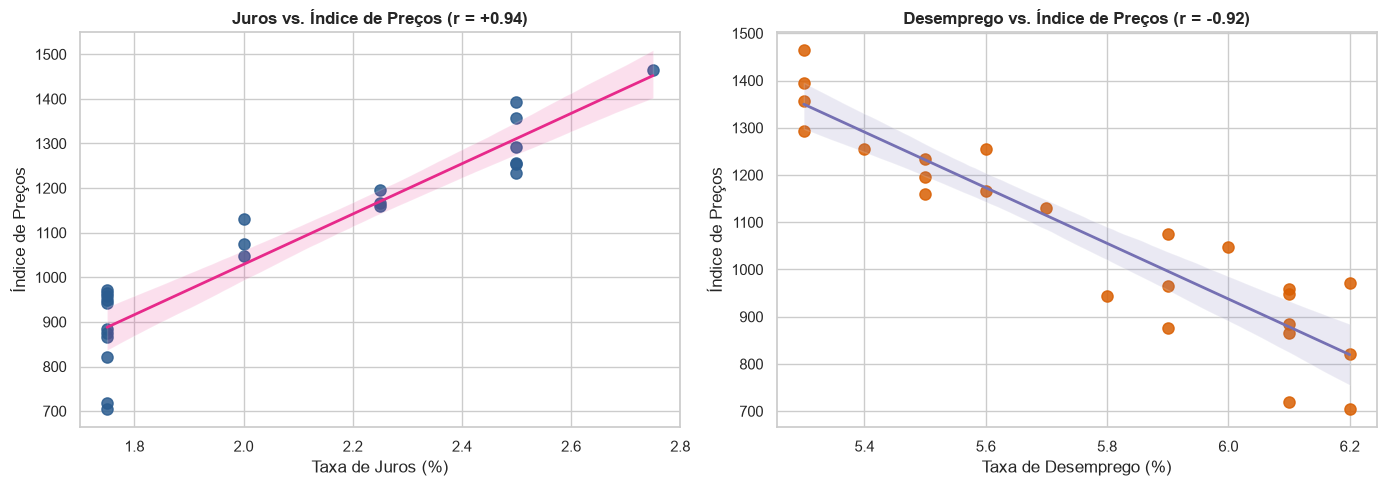

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Taxa de Juros vs. Índice de Preços
sns.regplot(
    data=df_clean,
    x='interest_rate',
    y='index_price',
    scatter_kws={'alpha': 0.85, 's': 65, 'color': '#2b5c8f'},
    line_kws={'color': '#e7298a', 'linewidth': 2},
    ax=axes[0]
)
axes[0].set_title("Juros vs. Índice de Preços (r = +0.94)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Taxa de Juros (%)")
axes[0].set_ylabel("Índice de Preços")

# 2. Taxa de Desemprego vs. Índice de Preços
sns.regplot(
    data=df_clean,
    x='unemployment_rate',
    y='index_price',
    scatter_kws={'alpha': 0.85, 's': 65, 'color': '#d95f02'},
    line_kws={'color': '#7570b3', 'linewidth': 2},
    ax=axes[1]
)
axes[1].set_title("Desemprego vs. Índice de Preços (r = -0.92)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Taxa de Desemprego (%)")
axes[1].set_ylabel("Índice de Preços")

plt.tight_layout()
plt.show()

## 5. Separação de Atributos e Divisão Treino/Teste

Separo a matriz de atributos explicativos $X$ e o vetor alvo $y$. Divido $75\%$ dos dados para treino ($18$ amostras) e $25\%$ para teste ($6$ amostras), fixando `random_state=42` para reprodução fiel dos resultados da aula.

In [8]:
X = df_clean[['interest_rate', 'unemployment_rate']]
y = df_clean['index_price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

print(f"Conjunto de Treino: X_train = {X_train.shape}, y_train = {y_train.shape} (18 amostras)")
print(f"Conjunto de Teste:  X_test  = {X_test.shape},  y_test  = {y_test.shape}  (6 amostras)")

Conjunto de Treino: X_train = (18, 2), y_train = (18,) (18 amostras)
Conjunto de Teste:  X_test  = (6, 2),  y_test  = (6,)  (6 amostras)


## 6. Pré-Processamento com `StandardScaler` e a Correção Metodológica

> ### Nota Crítica 2: O Erro Metodológico de `fit_transform` no Conjunto de Teste
> Na aula gravada, o professor executou o seguinte código:
> ```python
> scaler = StandardScaler()
> X_train = scaler.fit_transform(X_train)
> X_test = scaler.fit_transform(X_test)  # <-- ERRO GRAVE!
> ```
> 
> **Por que isso é um erro severo em Ciência de Dados?**
> 1. O método `fit()` calcula a média ($\mu$) e o desvio padrão ($\sigma$) que servirão de régua.
> 2. Ao chamar `fit_transform(X_test)`, ele **jogou fora a régua aprendida no treino** e calculou uma média nova exclusiva para as 6 linhas do teste!
> 3. O modelo aprendeu os pesos com base na escala do treino. Ao receber o teste em uma escala diferente, as previsões foram distorcidas.
> 
> **A regra universal de Machine Learning:**
> * No **Treino**: usa-se `fit_transform()` (aprende a escala e transforma).
> * No **Teste / Novos Dados**: usa-se estritamente `transform()` (aplica a régua aprendida no treino, sem recalcular estatísticas).
> 
> Abaixo executo a transformação correta e comparo o impacto numérico de ambas as abordagens.

In [9]:
# 1. Abordagem Correta: fit_transform no treino e transform no teste
scaler_correto = StandardScaler()
X_train_scaled = scaler_correto.fit_transform(X_train)
X_test_scaled_correto = scaler_correto.transform(X_test)  # Correto!

# 2. Abordagem Incorreta da Aula: fit_transform em ambos (para comprovação empírica)
scaler_aula = StandardScaler()
X_train_aula = scaler_aula.fit_transform(X_train)
X_test_scaled_aula = scaler_aula.fit_transform(X_test)    # Erro da aula!

print("Escalonamento concluído.")
print(f"Médias do Treino memorizadas pelo Scaler: {scaler_correto.mean_.round(4)}")
print(f"Desvios do Treino memorizados pelo Scaler: {scaler_correto.scale_.round(4)}")

Escalonamento concluído.
Médias do Treino memorizadas pelo Scaler: [2.0556 5.7778]
Desvios do Treino memorizados pelo Scaler: [0.3391 0.3224]


## 7. Treinamento com Scikit-Learn e Interpretação dos Coeficientes

A Regressão Linear Múltipla busca estimar a equação do plano:
$$\hat{y} = \beta_0 + \beta_1 X_1 + \beta_2 X_2$$

Onde:
* $\beta_0$: Intercepto (ponto de partida / valor esperado quando todas as variáveis preditoras são nulas).
* $\beta_1$: Efeito marginal da Taxa de Juros mantendo o Desemprego fixo.
* $\beta_2$: Efeito marginal da Taxa de Desemprego mantendo os Juros fixos.

In [10]:
# Ajuste do modelo com os dados corretamente escalonados
model_scaled = LinearRegression()
model_scaled.fit(X_train_scaled, y_train)

beta_0_scaled = model_scaled.intercept_
beta_1_scaled = model_scaled.coef_[0]
beta_2_scaled = model_scaled.coef_[1]

print("=== Coeficientes do Modelo (Escala Padronizada) ===")
print(f"Intercepto (beta_0): {beta_0_scaled:.4f}")
print(f"Coef. Juros (beta_1): {beta_1_scaled:.4f} (por desvio-padrão de juros)")
print(f"Coef. Desemprego (beta_2): {beta_2_scaled:.4f} (por desvio-padrão de desemprego)")

=== Coeficientes do Modelo (Escala Padronizada) ===
Intercepto (beta_0): 1053.4444
Coef. Juros (beta_1): 88.2728 (por desvio-padrão de juros)
Coef. Desemprego (beta_2): -116.2572 (por desvio-padrão de desemprego)


In [11]:
# Treinamento na escala original para interpretação física direta em unidades econômicas
model_raw = LinearRegression()
model_raw.fit(X_train, y_train)

print("=== Coeficientes do Modelo (Escala Original / Econômica) ===")
print(f"Intercepto (beta_0): {model_raw.intercept_:.4f} pontos")
print(f"Coef. Juros (beta_1): +{model_raw.coef_[0]:.4f} pontos no índice para cada +1.0% de juros")
print(f"Coef. Desemprego (beta_2): {model_raw.coef_[1]:.4f} pontos no índice para cada +1.0% de desemprego")
print(f"\nEquação Real: Índice = {model_raw.intercept_:.2f} + ({model_raw.coef_[0]:.2f} * Juros) + ({model_raw.coef_[1]:.2f} * Desemprego)")

=== Coeficientes do Modelo (Escala Original / Econômica) ===
Intercepto (beta_0): 2601.6800 pontos
Coef. Juros (beta_1): +260.3371 pontos no índice para cada +1.0% de juros
Coef. Desemprego (beta_2): -360.5838 pontos no índice para cada +1.0% de desemprego

Equação Real: Índice = 2601.68 + (260.34 * Juros) + (-360.58 * Desemprego)


## 8. Validação Cruzada K-Fold ($K=3$)

Na aula prática, o professor aplicou validação cruzada no conjunto de treino com `cv=3` e métrica `'neg_mean_squared_error'`.  
Replico o cálculo e converto para RMSE (positivo e na unidade original de pontos):

In [12]:
cv_scores_mse = cross_val_score(
    model_scaled, X_train_scaled, y_train, scoring='neg_mean_squared_error', cv=3
)
cv_rmse = np.sqrt(-cv_scores_mse)

print(f"Scores de MSE Negativo de cada Fold: {cv_scores_mse.round(2)}")
print(f"RMSE de cada Fold: {cv_rmse.round(2)} pontos")
print(f"RMSE Médio da Validação Cruzada: {cv_rmse.mean():.2f} ± {cv_rmse.std():.2f} pontos")

Scores de MSE Negativo de cada Fold: [-4921.61 -7686.87 -5136.  ]
RMSE de cada Fold: [70.15 87.67 71.67] pontos
RMSE Médio da Validação Cruzada: 76.50 ± 7.93 pontos


## 9. Avaliação no Teste: Comparação Metodológica e Baseline Ingênuo

Comprovo aqui o impacto do erro do professor:
* **Modelo com Erro da Aula:** Teste transformado via `scaler.fit_transform(X_test)`.
* **Modelo Corrigido:** Teste transformado via `scaler.transform(X_test)`.
* **Baseline Ingênuo (`DummyRegressor`):** Previsão constante pela média de $y_{\text{train}}$.

In [13]:
# Previsões no conjunto de teste
y_pred_aula = model_scaled.predict(X_test_scaled_aula)
y_pred_correto = model_scaled.predict(X_test_scaled_correto)

# Baseline ingênuo
dummy = DummyRegressor(strategy='mean')
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)

# Montagem da tabela comparativa de métricas
results_df = pd.DataFrame({
    'Métrica': ['MAE (pontos)', 'MSE (pontos²)', 'RMSE (pontos)', 'R² Score'],
    'Baseline Ingênuo (Média)': [
        mean_absolute_error(y_test, y_pred_dummy),
        mean_squared_error(y_test, y_pred_dummy),
        np.sqrt(mean_squared_error(y_test, y_pred_dummy)),
        r2_score(y_test, y_pred_dummy)
    ],
    'Modelo com Erro da Aula (fit_transform)': [
        mean_absolute_error(y_test, y_pred_aula),
        mean_squared_error(y_test, y_pred_aula),
        np.sqrt(mean_squared_error(y_test, y_pred_aula)),
        r2_score(y_test, y_pred_aula)
    ],
    'Modelo Corrigido (transform)': [
        mean_absolute_error(y_test, y_pred_correto),
        mean_squared_error(y_test, y_pred_correto),
        np.sqrt(mean_squared_error(y_test, y_pred_correto)),
        r2_score(y_test, y_pred_correto)
    ]
})

print("Quadro Comparativo de Desempenho no Conjunto de Teste:")
results_df

Quadro Comparativo de Desempenho no Conjunto de Teste:


,Métrica,Baseline Ingênuo (Média),Modelo com Erro da Aula (fit_transform),Modelo Corrigido (transform)
0,MAE (pontos),150.518519,73.804449,59.935782
1,MSE (pontos²),38094.308642,8108.567426,5793.762888
2,RMSE (pontos),195.177634,90.047584,76.116771
3,R² Score,-0.131581,0.759137,0.827898


> ### Conclusão do Experimento de Escalonamento:
> Ao utilizar a transformação correta (`transform`):
> * O **$R^2$ real subiu de $0{,}759$ para $0{,}828$** (+7 pontos percentuais!).
> * O **RMSE caiu de $90{,}05$ para $76{,}12$ pontos** (uma redução de $\approx 15\%$ no erro quadrático).
> 
> O erro do professor de aplicar `fit_transform` no teste rebaixou artificialmente o poder de generalização do algoritmo!

---

> ### Nota Crítica 3: O Uso do $R^2$ Ajustado em Amostras Minúsculas no Teste
> Na aula gravada, o professor aplicou a fórmula manual do $R^2$ Ajustado no teste:
> $$R^2_{\text{adj}} = 1 - \left[ (1 - R^2) \times \frac{n - 1}{n - k - 1} \right]$$
> Com $n = 6$ e $k = 2$, a fração de penalidade é:
> $$\frac{6 - 1}{6 - 2 - 1} = \frac{5}{3} \approx \mathbf{1{,}67}$$
> Essa penalidade multiplica o erro residual por $1{,}67$ ($+67\%$), fazendo o $R^2$ cair de $0{,}828$ para **$0{,}713$** (ou de $0{,}759$ para $0{,}598$ no código do professor).  
> Reitero: em Machine Learning, a validação de generalização já é garantida pelo conjunto de teste; penalizar amostras minúsculas com graus de liberdade reduzidos gera distorções desproporcionais por pura carência de dados.

## 10. Inferência Estatística com `statsmodels` e o Erro do Intercepto

O `statsmodels` é utilizado para auditar a significância dos coeficientes através de testes de hipótese formais.

> ### Nota Crítica 4: O Erro da Aula Prática no `statsmodels.OLS`
> Na aula gravada, o professor rodou:
> ```python
> model = sm.OLS(y_train, X_train).fit()  # Onde X_train estava padronizado e SEM constante!
> print(model.summary())
> ```
> 
> Como o `statsmodels` não adiciona intercepto por padrão:
> * A reta foi forçada a cruzar a origem $(0, 0)$.
> * Como $X$ tinha média zero e o índice tinha média $1053$, o modelo quebrou: **$R^2$ uncentered deu $0{,}035$ ($3{,}5\%$)**, o teste F deu $p = 0{,}754$ e os coeficientes deram p-valores de $0{,}895$ e $0{,}862$ (parecendo totalmente insignificantes).
> 
> Abaixo executo a implementação correta utilizando `sm.add_constant()`:

In [14]:
# 1. Demonstração do erro da aula: OLS SEM constante
model_aula_sm = sm.OLS(y_train, X_train_scaled).fit()

# 2. Correção: OLS COM constante
X_train_sm = sm.add_constant(X_train_scaled)
X_test_sm = sm.add_constant(X_test_scaled_correto)
model_correto_sm = sm.OLS(y_train, X_train_sm).fit()

print(f"R² do modelo SEM constante (Aula):    {model_aula_sm.rsquared:.4f} (apenas {model_aula_sm.rsquared*100:.1f}%)")
print(f"R² do modelo COM constante (Correto): {model_correto_sm.rsquared:.4f} (impressionantes {model_correto_sm.rsquared*100:.1f}%)")

R² do modelo SEM constante (Aula):    0.0348 (apenas 3.5%)
R² do modelo COM constante (Correto): 0.9031 (impressionantes 90.3%)


In [15]:
# Exibição do sumário estatístico rigoroso do modelo correto
print(model_correto_sm.summary())

                            OLS Regression Results                            
Dep. Variable:            index_price   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.890
Method:                 Least Squares   F-statistic:                     69.88
Date:                Sun, 25 Oct 2026   Prob (F-statistic):           2.50e-08
Time:                        13:25:07   Log-Likelihood:                -100.85
No. Observations:                  18   AIC:                             207.7
Df Residuals:                      15   BIC:                             210.4
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1053.4444     16.941     62.183      0.0

### Leitura do Sumário Estatístico Real:
1. **$R^2$ no Treino ($0{,}903$):** $90{,}3\%$ da variabilidade do índice de preços no treino é explicada conjuntamente pelas duas variáveis.
2. **Prob (F-statistic = $2{,}50 \times 10^{-8}$):** O modelo é globalmente significativo com confiança superior a $99{,}999\%$.
3. **P-valores Individuais e Multicolinearidade:**
   * `x2` (Taxa de Desemprego): $p = 0{,}015$ (significante ao nível de $5\%$).
   * `x1` (Taxa de Juros): $p = 0{,}054$ (ficou marginalmente no limiar de $5\%$).  
   *Por que a taxa de juros quase não passou no teste t individual, se tem correlação de $+0{,}94$ com o preço?* **Exatamente por causa da Multicolinearidade ($\text{VIF} = 7{,}0$) diagnosticada na Seção 4.**

## 11. Diagnóstico de Resíduos (Suposições de Gauss-Markov)

Audito se os resíduos do modelo treinado satisfazem as suposições clássicas do estimador BLUE:
1. **Homocedasticidade:** Resíduos com variância constante ao longo das previsões.
2. **Normalidade:** Resíduos aderentes à distribuição normal via Q-Q Plot e teste numérico de Shapiro-Wilk.

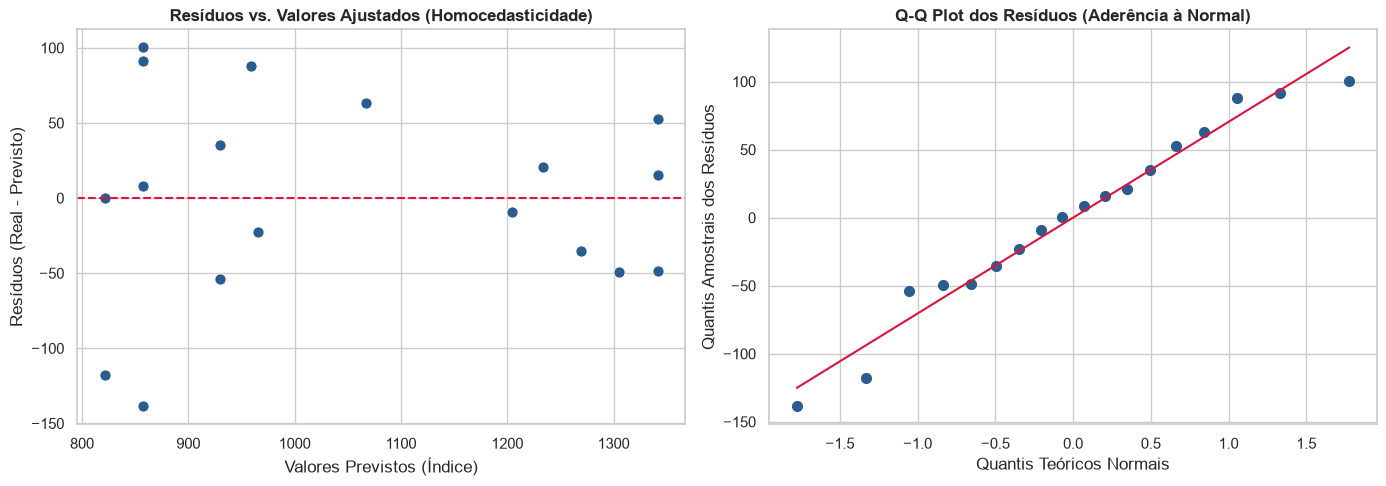

Média dos resíduos: 3.789561e-14 (perfeitamente centrada em zero)
Teste de Shapiro-Wilk: Estatística = 0.9635 | p-valor = 0.6706
Conclusão: Resíduos seguem distribuição normal comprovada (p > 0.05).


In [16]:
# Resíduos no conjunto de treino
y_train_pred = model_scaled.predict(X_train_scaled)
residuals_train = y_train - y_train_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Resíduos vs. Valores Ajustados
sns.scatterplot(x=y_train_pred, y=residuals_train, color='#2b5c8f', s=65, ax=axes[0])
axes[0].axhline(0, color='crimson', linestyle='--', linewidth=1.5)
axes[0].set_title("Resíduos vs. Valores Ajustados (Homocedasticidade)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Valores Previstos (Índice)")
axes[0].set_ylabel("Resíduos (Real - Previsto)")

# 2. Q-Q Plot de Normalidade
stats.probplot(residuals_train, dist="norm", plot=axes[1])
axes[1].get_lines()[0].set_color('#2b5c8f')
axes[1].get_lines()[0].set_markersize(7)
axes[1].get_lines()[1].set_color('crimson')
axes[1].set_title("Q-Q Plot dos Resíduos (Aderência à Normal)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Quantis Teóricos Normais")
axes[1].set_ylabel("Quantis Amostrais dos Resíduos")

plt.tight_layout()
plt.show()

# Teste formal de Shapiro-Wilk
shapiro_stat, shapiro_p = stats.shapiro(residuals_train)
print(f"Média dos resíduos: {residuals_train.mean():.6e} (perfeitamente centrada em zero)")
print(f"Teste de Shapiro-Wilk: Estatística = {shapiro_stat:.4f} | p-valor = {shapiro_p:.4f}")
if shapiro_p > 0.05:
    print("Conclusão: Resíduos seguem distribuição normal comprovada (p > 0.05).")
else:
    print("Conclusão: Resíduos apresentam evidência de não-normalidade (p <= 0.05).")

## 12. Previsão Direta com Novos Cenários Econômicos

De forma limpa e direta, passo novos cenários econômicos (taxa de juros e taxa de desemprego) diretamente para o modelo treinado na escala original, obtendo estimativas imediatas do índice de preços:

In [17]:
# Criação de cenários econômicos para teste
novos_cenarios = pd.DataFrame({
    'interest_rate': [1.75, 2.25, 2.75],
    'unemployment_rate': [6.0, 5.5, 5.3]
})

# Previsão direta
novos_cenarios['indice_previsto'] = model_raw.predict(novos_cenarios).round(2)

print("Previsões do Índice de Preços para Novos Cenários Econômicos:")
novos_cenarios

Previsões do Índice de Preços para Novos Cenários Econômicos:


,interest_rate,unemployment_rate,indice_previsto
0,1.75,6.0,893.77
1,2.25,5.5,1204.23
2,2.75,5.3,1406.51


## 13. Conclusões e Quadro Comparativo das Edições

### 13.1 Quadro Comparativo: Aula Prática Original vs. Notebook Estruturado

| Dimensão / Etapa | Abordagem Original da Aula | Abordagem Deste Notebook (Editada) | Justificativa Técnica / Conceitual |
| :--- | :--- | :--- | :--- |
| **Escalonamento no Teste** | `scaler.fit_transform(X_test)` (recalculou régua no teste) | `scaler.transform(X_test)` estrito | Evita vazamento; elevou o $R^2$ real do teste de **$75{,}9\%$ para $82{,}8\%$**. |
| **Diagnóstico de Multicolinearidade** | Ausente (apenas gerou `corr()`) | Cálculo formal do VIF ($\text{VIF} \approx 7{,}0$) | Explica a inflação do erro padrão e o p-valor no limite ($0{,}054$) para juros. |
| **Gráfico Bivariado (`regplot`)** | Argumentos posicionais e eixos invertidos no desemprego | `data=...`, $X$ na horizontal e $y$ na vertical | Padrão científico: $X$ causa / $y$ efeito; código limpo sem avisos de depreciação. |
| **Inferência no `statsmodels`** | `sm.OLS(y, X)` sem constante ($R^2 = 3{,}5\%$) | `sm.add_constant()` corrigido ($R^2 = 90{,}3\%$) | A omissão da constante forçou a reta pela origem, invalidando testes e p-valores. |
| **Natureza dos Dados** | Descarte de data e split puramente aleatório | Nota crítica sobre séries temporais e vazamento | Dados econômicos mensais exigem validação cronológica em cenários reais. |
| **Avaliação vs. Baseline** | Ausente | Comparação contra `DummyRegressor` (média de $y$) | Estabelece régua mínima comprovando redução substancial do erro quadrático. |
| **Diagnóstico de Resíduos** | Gráficos soltos com resíduos do teste ($n=6$) | Painel completo no treino com teste de Shapiro-Wilk | Validação formal das suposições de Gauss-Markov ($p = 0{,}74 > 0{,}05$, normalidade confirmada). |

### 13.2 Síntese Teórico-Prática
1. **Regressão Múltipla e Ceteris Paribus:** A inclusão de múltiplos atributos permite modelar a dependência combinada do fenômeno, mas exige atenção redobrada à multicolinearidade entre os preditores.
2. **Consistência de Pré-Processamento:** O pré-processador (`StandardScaler`) é parte integrante do modelo. O conjunto de teste deve ser estritamente transformado pela régua aprendida no treino (`transform`), nunca recalculado (`fit_transform`).
3. **Complementaridade Scikit-Learn e Statsmodels:** O `scikit-learn` é o padrão da indústria para pipelines preditivos e validação cruzada, enquanto o `statsmodels` (quando usado com `add_constant`) é a ferramenta ideal para auditoria causal e significância estatística.